# 02 - Descriptive Statistics for Numerical Columns

**Project:** German Credit Risk
**Dataset:** `data/german_credit_data.csv`
**Author:** Divya Akbari

**Goal of this notebook**
1. Give an overview of all columns, their types and missing values.
2. Calculate descriptive statistics for the numerical columns: Age, Credit amount and Duration.
3. Compare the numerical columns between good-risk and bad-risk customers.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 120)

df = pd.read_csv('data/german_credit_data.csv')
df = df.drop(columns=['Unnamed: 0'])   # row number only, not real data
print(df.shape)

(1000, 10)


## 1. Column overview

In [2]:
overview = pd.DataFrame({
    'Data type': df.dtypes.astype(str),
    'Unique values': df.nunique(),
    'Missing values': df.isna().sum(),
    'Missing (%)': (df.isna().mean() * 100).round(1)
})
overview

,Data type,Unique values,Missing values,Missing (%)
Age,int64,53,0,0.0
Sex,str,2,0,0.0
Job,int64,4,0,0.0
Housing,str,3,0,0.0
Saving accounts,str,4,183,18.3
Checking account,str,3,394,39.4
Credit amount,int64,921,0,0.0
Duration,int64,33,0,0.0
Purpose,str,8,0,0.0
Risk,str,2,0,0.0


In [3]:
print('Duplicate rows:', df.duplicated().sum())

Duplicate rows: 0


**Column types**

| Type | Columns |
|---|---|
| Numerical | Age, Credit amount (in Deutsche Mark), Duration (in months) |
| Categorical | Sex, Job, Housing, Saving accounts, Checking account, Purpose |
| Target | Risk |

`Job` is stored as a number (0 to 3) but it is really a **category** (a skill level), so it is treated as categorical:
0 = unskilled and non-resident, 1 = unskilled and resident, 2 = skilled, 3 = highly skilled.

Only `Saving accounts` (183 missing) and `Checking account` (394 missing) have missing values.
They are kept as a separate **"missing"** group here, because a missing value may mean the customer has no account of that type.

## 2. Descriptive statistics for numerical columns

In [4]:
num_cols = ['Age', 'Credit amount', 'Duration']

desc = df[num_cols].describe().T
desc['skewness'] = df[num_cols].skew()
desc['kurtosis'] = df[num_cols].kurt()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
Age,1000.0,35.55,11.38,19.0,27.0,33.0,42.00,75.0,1.02,0.60
Credit amount,1000.0,3271.26,2822.74,250.0,1365.5,2319.5,3972.25,18424.0,1.95,4.29
Duration,1000.0,20.90,12.06,4.0,12.0,18.0,24.00,72.0,1.09,0.92


### Outliers (IQR rule)
A value is called an outlier if it is more than 1.5 x IQR above the 3rd quartile or below the 1st quartile.

In [5]:
rows = []
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    rows.append([col, q1, q3, iqr, upper, count, round(count / len(df) * 100, 1)])

outliers = pd.DataFrame(rows, columns=['Column', 'Q1', 'Q3', 'IQR', 'Upper limit', 'Outliers', 'Outliers (%)'])
outliers

,Column,Q1,Q3,IQR,Upper limit,Outliers,Outliers (%)
0,Age,27.0,42.00,15.00,64.500,23,2.3
1,Credit amount,1365.5,3972.25,2606.75,7882.375,72,7.2
2,Duration,12.0,24.00,12.00,42.000,70,7.0


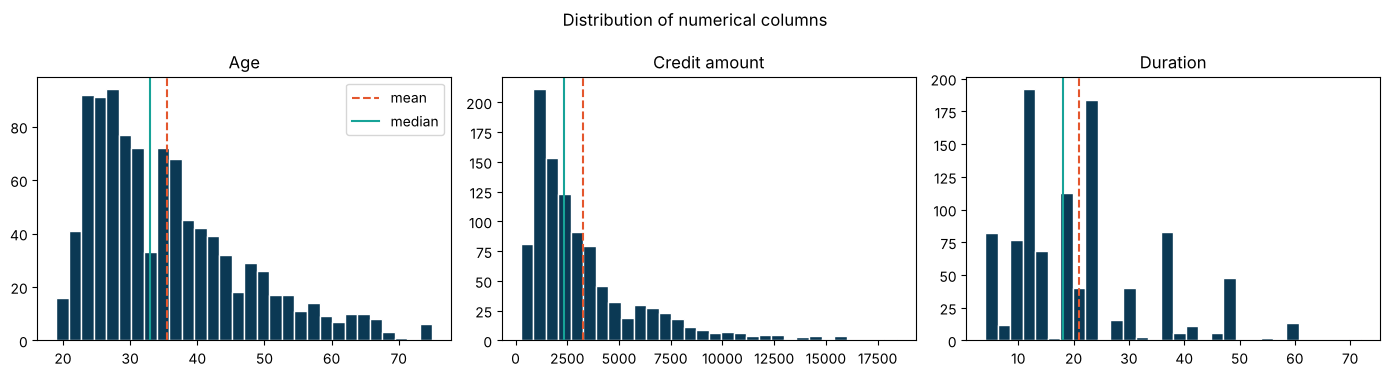

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col in zip(axes, num_cols):
    ax.hist(df[col], bins=30, color='#0B3954', edgecolor='white')
    ax.axvline(df[col].mean(), color='#E4572E', linestyle='--', label='mean')
    ax.axvline(df[col].median(), color='#17A398', linestyle='-', label='median')
    ax.set_title(col)
axes[0].legend()
plt.suptitle('Distribution of numerical columns')
plt.tight_layout()
plt.show()

### Numerical columns by Risk

In [7]:
by_risk = df.groupby('Risk')[num_cols].agg(['mean', 'median']).round(1)
by_risk

Age        Credit amount         Duration       
      mean median          mean  median     mean median
Risk                                                   
bad   34.0   31.0        3938.1  2574.5     24.9   24.0
good  36.2   34.0        2985.5  2244.0     19.2   18.0

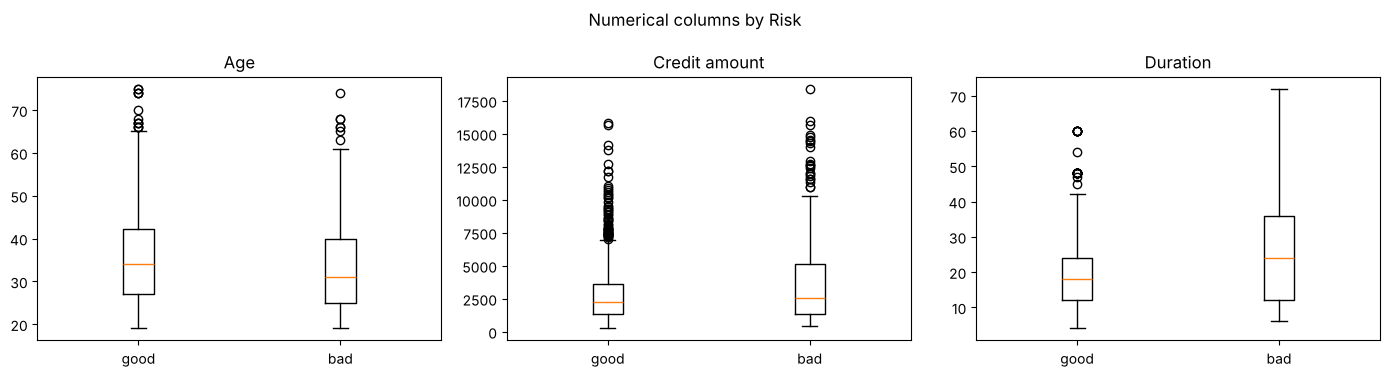

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col in zip(axes, num_cols):
    data = [df.loc[df['Risk'] == 'good', col], df.loc[df['Risk'] == 'bad', col]]
    ax.boxplot(data)
    ax.set_xticklabels(['good', 'bad'])
    ax.set_title(col)
plt.suptitle('Numerical columns by Risk')
plt.tight_layout()
plt.show()

In [9]:
df[num_cols].corr().round(2)

,Age,Credit amount,Duration
Age,1.00,0.03,-0.04
Credit amount,0.03,1.00,0.62
Duration,-0.04,0.62,1.00


**What the numbers show**
- All three columns are **right-skewed** (mean above median): most loans are small and short, with a few very large or long ones.
- `Credit amount` is the most skewed (skewness 1.95) and has the most outliers (72 loans above 7,882 DM).
  These are real loans, not errors, so they are kept; a log transform can be used in modelling.
- `Duration` and `Credit amount` are clearly related (correlation 0.62): bigger loans are taken over longer periods.
- Bad-risk customers borrow **more** (mean 3,938 vs 2,986 DM) for **longer** (mean 24.9 vs 19.2 months) and are slightly **younger** (mean 34.0 vs 36.2 years).

## 3. Quick checks

In [10]:
q1, q3 = df['Credit amount'].quantile([0.25, 0.75])
credit_outliers = (df['Credit amount'] > q3 + 1.5 * (q3 - q1)).sum()

checks = {
    'Dataset has 1,000 rows': len(df) == 1000,
    'No duplicate rows': df.duplicated().sum() == 0,
    'Numerical columns have no missing values': df[num_cols].isna().sum().sum() == 0,
    'Age is between 18 and 100': df['Age'].between(18, 100).all(),
    'Credit amount is positive': (df['Credit amount'] > 0).all(),
    'Duration is positive': (df['Duration'] > 0).all(),
    'Good and bad groups add up to 1,000': df.groupby('Risk').size().sum() == 1000,
    'Credit amount has 72 high outliers': credit_outliers == 72,
}
for name, passed in checks.items():
    print('PASS' if passed else 'FAIL', '-', name)
assert all(checks.values())
print()
print(f'All {len(checks)} checks passed')

PASS - Dataset has 1,000 rows
PASS - No duplicate rows
PASS - Numerical columns have no missing values
PASS - Age is between 18 and 100
PASS - Credit amount is positive
PASS - Duration is positive
PASS - Good and bad groups add up to 1,000
PASS - Credit amount has 72 high outliers

All 8 checks passed
